# 15 Where were the 2019-04-15 events? Joint relocation of A1–A3 with the 2025 swarm

Notebooks 13 and 14 showed three small events on 2019-04-15 (A1 14:17:35, A2 14:17:39, A3 14:43:15 UTC) that match the swarm templates. You judged them real. Here they are relocated **together with all 235 swarm events**, with the swarm's own settings (decision D22):
- FMF detections, A1–A3 included, carry picks inherited from their templates;
- catalog differential times are used among the 28 references only, so the detections are tied in by waveform cross-correlation alone (5–20 Hz, CC ≥ 0.7);
- 1,000 bootstrap replicas, then the 25 m rule.

**Two runs.**
- **2019A.** The long scan had kept only the 22 FMF stations' files for the 2019 day, so A1–A3 were tied in at 8–9 stations.
- **2019A_full.** Every KS station within 100 km with data on 2019-04-15 (53) was then fetched, as the swarm events had.

**The two runs are identical, by construction.** Cross-correlation windows on picks, and an FMF detection's picks are inherited from its template event (D22). A1–A3 inherit picks only at the 8–9 stations where their templates (400001, 400007) were picked by PhaseNet+, and those stations already had data in the first run. The table below lists them. Every swarm detection is limited the same way (median 4 P and 10 S inherited picks), so A1–A3 are treated exactly like the swarm detections. More stations for them would need their own picks, which is a change of method.

**Checks.**
- How the 2019-to-2025 links fit, station by station. Several stations changed instruments between 2019 and 2025, and a timing or polarity change shows up as a constant offset.
- Whether the result survives dropping suspect stations: each 2019 event is re-solved against the fixed positions of the best-located swarm events.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore', message='Catching unstable calculation')
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from obspy.taup import TauPyModel
from obspy.geodetics import gps2dist_azimuth
pd.set_option('display.width', 220)
RUNS = {'2019A': '22 FMF stations kept for 2019', '2019A_full': 'all 53 stations for 2019'}
CAT = {k: pd.read_csv(f'{DL}/catalogs/imsil_fmf_relocated_{k}.csv', dtype={'event_id': str}) for k in RUNS}
R25 = {k: pd.read_csv(f'{DL}/catalogs/reference_25m_fmf_{k}/DL_reference_25m.csv', dtype={'event_id': str}) for k in RUNS}
ADOPT = pd.read_csv(f'{DL}/catalogs/imsil_fmf_relocated.csv', dtype={'event_id': str})
AID = {'20190415141735': 'A1', '20190415141739': 'A2', '20190415144315': 'A3'}
for k, c in CAT.items():
    c['emax'] = c[['ex95_m', 'ey95_m', 'ez95_m']].max(axis=1)
    print(f'{k} ({RUNS[k]}): relocated {len(c)} (swarm {int((~c.event_id.isin(AID)).sum())}, 2019 events {int(c.event_id.isin(AID).sum())}); 25 m rule {len(R25[k])}')

2019A (22 FMF stations kept for 2019): relocated 215 (swarm 212, 2019 events 3); 25 m rule 102
2019A_full (all 53 stations for 2019): relocated 215 (swarm 212, 2019 events 3); 25 m rule 102


In [2]:
import glob, obspy
rows = []
for k in RUNS:
    for eid, lab in AID.items():
        fs = glob.glob(f'{DL}/runs/hypodd_fmf_{k}/waveforms_100km/{eid}/*Z.sac'); pk = []
        for f in fs:
            h = obspy.read(f, headonly=True)[0].stats.sac; p_, s_ = h.get('a', -12345) > -1e4, h.get('t0', -12345) > -1e4
            if p_ or s_: pk.append(f.split('.')[-3] + ('(P,S)' if p_ and s_ else '(P)' if p_ else '(S)'))
        rows.append(dict(run=k, event=lab, stations_with_data=len(fs), stations_with_inherited_picks=len(pk), picks=', '.join(sorted(pk))))
display(pd.DataFrame(rows))
inp = pd.read_csv(f'{DL}/runs/hypodd_fmf_2019A_full/fmf_relocation_input.csv'); dd = inp[inp.kind == 'detection']
print(f'all FMF detections in the run: inherited picks per detection, median {dd.n_P.median():.0f} P and {dd.n_S.median():.0f} S')

,run,event,stations_with_data,stations_with_inherited_picks,picks
0,2019A,A1,21,9,"DGHA(S), GKSA(S), IMSB(S), JEU2(S), JLSA(S), K..."
1,2019A,A2,21,8,"DGHA(S), GKSA(S), IMSB(P,S), JEU2(S), JLSA(S),..."
2,2019A,A3,21,8,"DGHA(S), GKSA(S), IMSB(P,S), JEU2(S), JLSA(S),..."
3,2019A_full,A1,53,9,"DGHA(S), GKSA(S), IMSB(S), JEU2(S), JLSA(S), K..."
4,2019A_full,A2,53,8,"DGHA(S), GKSA(S), IMSB(P,S), JEU2(S), JLSA(S),..."
5,2019A_full,A3,53,8,"DGHA(S), GKSA(S), IMSB(P,S), JEU2(S), JLSA(S),..."


all FMF detections in the run: inherited picks per detection, median 4 P and 10 S


## 1. Positions relative to the swarm's fault plane

The plane is Haenam's SVD fit (`joint_science.plane`) to the events that meet the 25 m rule in each run. Each event is given three coordinates:
- `along_east`: along strike, positive to the east;
- `up_dip`: up the plane, positive upward;
- `normal`: distance from the plane. The plane strikes E–W, so a negative value is south of the plane.

For comparison, 99 % of the swarm's 25 m events lie within the `normal` distance printed below.

In [3]:
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
FR = {}
for k, c in CAT.items():
    r25 = c[c.event_id.isin(R25[k].event_id)]; lat0, lon0, z0 = r25.latitude.mean(), r25.longitude.mean(), r25.depth_km.mean()
    xyz = lambda d: np.c_[(d.longitude - lon0) * 111.19e3 * np.cos(np.radians(lat0)), (d.latitude - lat0) * 111.19e3, (d.depth_km - z0) * 1e3]
    P = plane(xyz(r25)); X = xyz(c) - P['center']; us = P['s'] if P['s'][0] > 0 else -P['s']
    nv = P['normal'] if P['normal'][1] > 0 else -P['normal']            # normal pointing north: negative = south of the plane
    c['along_east'], c['up_dip'], c['normal'] = X @ us, -(X @ P['down']), X @ nv
    c['E_m'], c['N_m'], c['Z_m'] = X[:, 0], X[:, 1], X[:, 2]
    FR[k] = dict(P=P, normal99=float(np.percentile(np.abs(c.normal[c.event_id.isin(R25[k].event_id)]), 99)))
rows = []
for k, c in CAT.items():
    for r in c[c.event_id.isin(AID)].itertuples():
        rows.append(dict(run=k, event=AID[r.event_id], origin=r.origin_time_reloc, along_east_m=r.along_east, up_dip_m=r.up_dip, normal_m=r.normal,
                         ex95_m=r.ex95_m, ey95_m=r.ey95_m, ez95_m=r.ez95_m, cc_links=r.cc_links, under_constrained=r.under_constrained, in_25m_set=r.event_id in set(R25[k].event_id)))
POS = pd.DataFrame(rows); display(POS.round(1))
for k in RUNS: print(f'{k}: plane {FR[k]["P"]["strike"]:.1f} / {FR[k]["P"]["dip"]:.1f}; 99 % of the 25 m events within {FR[k]["normal99"]:.0f} m of the plane')

,run,event,origin,along_east_m,up_dip_m,normal_m,ex95_m,ey95_m,ez95_m,cc_links,under_constrained,in_25m_set
0,2019A,A1,2019-04-15 14:17:35.390,34.9,-85.9,-268.6,129.9,32.1,66.8,355,True,False
1,2019A,A2,2019-04-15 14:17:39.460,142.5,-9.0,-266.0,86.7,35.4,45.4,347,False,False
2,2019A,A3,2019-04-15 14:43:15.360,186.2,-23.8,-305.1,82.7,20.4,36.5,387,False,False
3,2019A_full,A1,2019-04-15 14:17:35.390,34.9,-85.9,-268.6,129.9,32.1,66.8,355,True,False
4,2019A_full,A2,2019-04-15 14:17:39.460,142.5,-9.0,-266.0,86.7,35.4,45.4,347,False,False
5,2019A_full,A3,2019-04-15 14:43:15.360,186.2,-23.8,-305.1,82.7,20.4,36.5,387,False,False


2019A: plane 269.0 / 88.3; 99 % of the 25 m events within 16 m of the plane
2019A_full: plane 269.0 / 88.3; 99 % of the 25 m events within 16 m of the plane


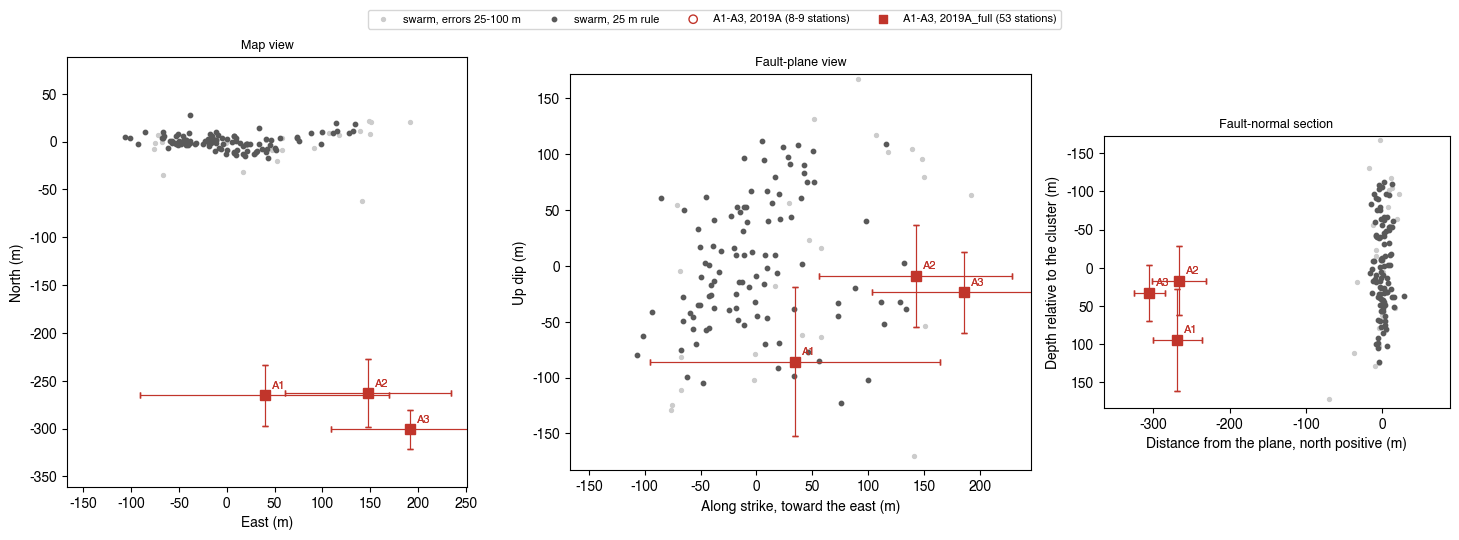

Shown: the swarm events inside the plotted area (25 m set dark; errors 25-100 m light). Error bars: the 95 % bootstrap half-width, (P97.5 - P2.5) / 2, in each direction (E-W, N-S, depth); along strike uses the E-W, fault-normal the N-S interval (the plane strikes E-W).


In [4]:
k = '2019A_full'; c = CAT[k]; sw = c[~c.event_id.isin(AID)]; g25 = sw[sw.event_id.isin(R25[k].event_id)]; g100 = sw[(sw.emax <= 100) & ~sw.event_id.isin(R25[k].event_id)]
A9 = CAT['2019A'][CAT['2019A'].event_id.isin(AID)].set_index('event_id'); AF = c[c.event_id.isin(AID)].set_index('event_id')
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1, 1, 0.75]))
views = (('E_m', 'N_m', 'East (m)', 'North (m)', 'ex95_m', 'ey95_m'), ('along_east', 'up_dip', 'Along strike, toward the east (m)', 'Up dip (m)', 'ex95_m', 'ez95_m'),
         ('normal', 'Z_m', 'Distance from the plane, north positive (m)', 'Depth relative to the cluster (m)', 'ey95_m', 'ez95_m'))
for a, (x, y, xl, yl, ex, ey) in zip(ax, views):
    a.scatter(g100[x], g100[y], s=8, color='0.8', label='swarm, errors 25-100 m'); a.scatter(g25[x], g25[y], s=10, color='0.35', label='swarm, 25 m rule')
    for (lab_run, T, mk) in (('2019A (8-9 stations)', A9, 'o'), ('2019A_full (53 stations)', AF, 's')):
        for eid, r in T.iterrows():
            a.errorbar(r[x], r[y], xerr=r[ex] if ex else None, yerr=r[ey], fmt=mk, ms=7, mfc='none' if mk == 'o' else '#c1352b', mec='#c1352b', ecolor='#c1352b', elinewidth=0.8, capsize=2)
            a.annotate(AID[eid], (r[x], r[y]), xytext=(5, 5), textcoords='offset points', fontsize=8, color='#c1352b')
    pts = pd.concat([g25[[x, y]], AF[[x, y]], A9[[x, y]]]); lo, hi = pts.min() - 60, pts.max() + 60
    a.set_xlim(lo[x], hi[x]); a.set_ylim(lo[y], hi[y]); a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect('equal', adjustable='box')
ax[2].invert_yaxis(); ax[1].set_title('Fault-plane view', fontsize=9); ax[0].set_title('Map view', fontsize=9); ax[2].set_title('Fault-normal section', fontsize=9)
ax[0].scatter([], [], marker='o', facecolor='none', edgecolor='#c1352b', label='A1-A3, 2019A (8-9 stations)'); ax[0].scatter([], [], marker='s', color='#c1352b', label='A1-A3, 2019A_full (53 stations)')
fig.legend(*ax[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=4, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()
print(f'Shown: the swarm events inside the plotted area (25 m set dark; errors 25-100 m light). Error bars: the 95 % bootstrap half-width, (P97.5 - P2.5) / 2, in each direction (E-W, N-S, depth); along strike uses the E-W, fault-normal the N-S interval (the plane strikes E-W).')

## 2. How the 2019-to-2025 links fit, station by station

Each cross-correlation link gives an observed differential time. The prediction uses the final locations, a straight ray from TauP (Kim & Kim 1983) and each event's origin-time shift solved by HypoDD (relocated minus catalog origin). On the well-located swarm pairs this prediction leaves a residual scatter (MAD) of about 7–8 ms. A station whose 2019-to-2025 links carry a large constant residual has a timing, polarity or orientation change between the two epochs. A shift near one S cycle (~100 ms at 10 Hz) is the signature of a cross-correlation that locked onto the wrong cycle.

2019A: 25 m swarm pairs: residual MAD 7.7 ms; links with a 2019 event: 2280 at 9 stations
2019A_full: 25 m swarm pairs: residual MAD 7.7 ms; links with a 2019 event: 2280 at 9 stations


,sta,ph,links,median_res_ms,mad_ms,median_cc,epoch_changed
0,MALA,S,588,-3.0,5.7,0.9,True
1,IMSB,S,534,-2.6,7.0,0.9,False
2,NAWB,S,295,93.3,14.1,0.8,True
3,GKSA,S,223,-3.8,11.5,0.8,False
4,JEU2,S,169,16.8,8.2,0.8,False
5,DGHA,S,140,-5.8,6.7,0.8,False
6,JLSA,S,126,-38.5,14.6,0.8,True
7,SUCA,S,116,-20.4,11.0,0.7,True
8,KCH2,S,50,-40.9,7.2,0.8,False
9,SUCA,P,11,22.0,4.3,0.7,True


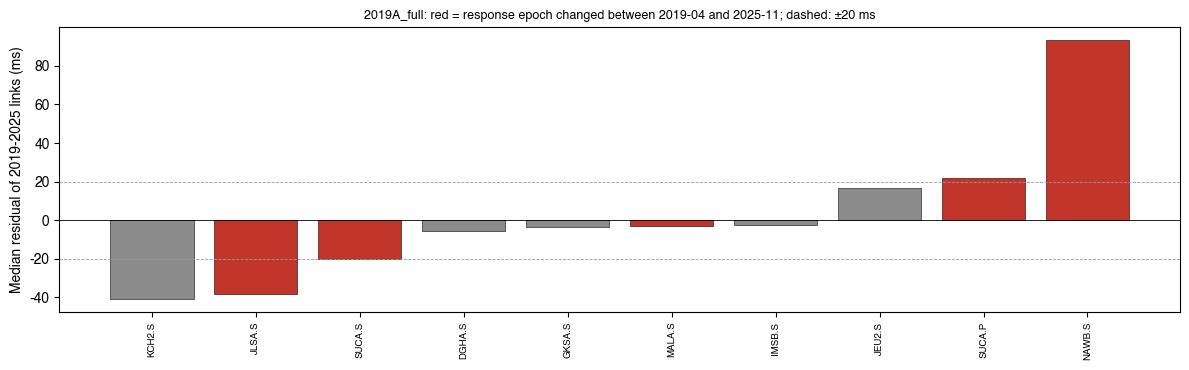

In [5]:
CHANGED = {'NAWB', 'SUCA', 'MALA', 'TAIA', 'JLSA', 'HAMB', 'JAGA', 'DUSB', 'KWJ2'}       # response epoch changes between 2019-04 and 2025-11 (notebook 13 setup)
def link_table(k):
    R = f'{DL}/runs/hypodd_fmf_{k}/2.HypoDD/02.dt.cc'
    rl = pd.read_csv(f'{R}/hypoDD.reloc', sep=r'\s+', header=None).set_index(0)
    o_rel = {i: UTCDateTime(int(r[10]), int(r[11]), int(r[12]), int(r[13]), int(r[14]), 0) + float(r[15]) for i, r in rl.iterrows()}
    o_cat = {}
    for ln in open(f'{R}/event.dat'):
        p = ln.split(); dd, tt = p[0], p[1].zfill(8); o_cat[int(p[-1])] = UTCDateTime(f'{dd[:4]}-{dd[4:6]}-{dd[6:8]}T{tt[:2]}:{tt[2:4]}:{tt[4:6]}.{tt[6:8]}')
    dO = {i: o_rel[i] - o_cat[i] for i in o_rel if i in o_cat}
    man = pd.read_csv(f'{DL}/runs/hypodd_fmf_{k}/event_manifest.csv', dtype={'event_id': str}); man['id'] = 200000 + man.event_idx
    aids = set(man.id[man.event_id.isin(AID)]); good = set(man.id[man.event_id.isin(R25[k].event_id)]); id2ev = dict(zip(man.id, man.event_id))
    st = pd.read_csv(f'{R}/station.dat', sep=r'\s+', header=None, names=['sta', 'lat', 'lon']).set_index('sta')
    lat0, lon0, dep0 = rl[1].mean(), rl[2].mean(), rl[3].mean(); KO = 111.19e3 * np.cos(np.radians(lat0)); KL = 111.19e3
    m = TauPyModel(f'/home/msseo/works/72.2025_Imsil_swarm/data/stations/taup/kim1983_buan.npz'); SV = {}
    def sv(s, ph):
        if (s, ph) not in SV:
            dist, az, _ = gps2dist_azimuth(lat0, lon0, st.lat[s], st.lon[s]); a = m.get_travel_times(dep0, dist / 1000 / 111.19, [ph.lower(), ph])[0]
            i = np.radians(a.takeoff_angle); v = 5.98 if ph == 'P' else 3.40
            SV[(s, ph)] = -np.array([np.sin(i) * np.sin(np.radians(az)), np.sin(i) * np.cos(np.radians(az)), np.cos(i)]) / (v * 1000)
        return SV[(s, ph)]
    xyz = {i: np.array([(r[2] - lon0) * KO, (r[1] - lat0) * KL, (r[3] - dep0) * 1000]) for i, r in rl.iterrows()}
    rows = []; cur = None
    for ln in open(f'{R}/dt.cc_0.7_combined'):
        p = ln.split()
        if p[0] == '#': cur = (int(p[1]), int(p[2])); continue
        isA = cur[0] in aids or cur[1] in aids; isG = cur[0] in good and cur[1] in good
        if (isA or isG) and cur[0] in xyz and cur[1] in xyz and cur[0] in dO and cur[1] in dO:
            pred = float(sv(p[0], p[3]) @ (xyz[cur[0]] - xyz[cur[1]])) + dO[cur[0]] - dO[cur[1]]
            rows.append(dict(i=cur[0], j=cur[1], sta=p[0][2:], ph=p[3], dt=float(p[1]), cc=float(p[2]), res_ms=(float(p[1]) - pred) * 1000,
                             kind='A-A' if (cur[0] in aids and cur[1] in aids) else ('A-2025' if isA else '25 m swarm pair')))
    return pd.DataFrame(rows), dict(aids=aids, good=good, xyz=xyz, dO=dO, sv=sv, id2ev=id2ev)
LT = {k: link_table(k) for k in RUNS}
for k in RUNS:
    d = LT[k][0]; g = d[d.kind == '25 m swarm pair']
    print(f'{k}: 25 m swarm pairs: residual MAD {np.median(np.abs(g.res_ms - g.res_ms.median())):.1f} ms; links with a 2019 event: {int((d.kind != "25 m swarm pair").sum())} at {d[d.kind != "25 m swarm pair"].sta.nunique()} stations')
d = LT['2019A_full'][0]; a = d[d.kind == 'A-2025']
ST = a.groupby(['sta', 'ph']).agg(links=('res_ms', 'size'), median_res_ms=('res_ms', 'median'), mad_ms=('res_ms', lambda x: float(np.median(np.abs(x - np.median(x))))), median_cc=('cc', 'median')).reset_index()
ST['epoch_changed'] = ST.sta.isin(CHANGED); ST = ST.sort_values('links', ascending=False).reset_index(drop=True); display(ST.round(1))
fig, ax = plt.subplots(figsize=(12, 3.8)); s_ = ST[ST.links >= 10].sort_values('median_res_ms')
ax.bar(range(len(s_)), s_.median_res_ms, color=np.where(s_.epoch_changed, '#c1352b', '0.55'), edgecolor='black', lw=0.4)
ax.set_xticks(range(len(s_))); ax.set_xticklabels([f'{r.sta}.{r.ph}' for r in s_.itertuples()], rotation=90, fontsize=7); ax.axhline(0, color='black', lw=0.6)
for y in (-20, 20): ax.axhline(y, color='0.6', ls='--', lw=0.6)
ax.set_ylabel('Median residual of 2019-2025 links (ms)'); ax.set_title('2019A_full: red = response epoch changed between 2019-04 and 2025-11; dashed: ±20 ms', fontsize=9)
plt.tight_layout(); plt.show()

## 3. Robustness: each 2019 event re-solved against the fixed swarm

Each 2019 event is solved alone (position plus origin shift, robust least squares) against the fixed final positions and origin shifts of the swarm's 25 m events. It is solved four times:
- with all its links;
- without the stations whose 2019-to-2025 links carry a median residual beyond ±20 ms;
- with stable-epoch stations only;
- with both exclusions.

If the off-plane position were an artifact of a few stations with timing changes, it would move when they are dropped.

In [6]:
def solve(k, a_id, drop=()):
    d, M = LT[k]; q = d[((d.i == a_id) & d.j.isin(M['good'])) | ((d.j == a_id) & d.i.isin(M['good']))]; q = q[~q.sta.isin(drop)]
    if q.sta.nunique() < 4: return dict(links=len(q), stations=q.sta.nunique())
    A_, y = [], []
    for r in q.itertuples():
        sg = 1 if r.i == a_id else -1; o = r.j if r.i == a_id else r.i; g = M['sv']('KS' + r.sta, r.ph)
        A_.append(np.r_[sg * g, sg]); y.append(r.dt + sg * (g @ M['xyz'][o]) + sg * M['dO'][o])
    A_, y = np.array(A_), np.array(y); w = np.ones(len(y))
    for _ in range(10):
        x, *_ = np.linalg.lstsq(A_ * w[:, None], y * w, rcond=None); r_ = y - A_ @ x; s = 1.4826 * np.median(np.abs(r_)); w = np.sqrt(np.minimum(1, 1.5 * s / np.maximum(np.abs(r_), 1e-9)))
    return dict(links=len(y), stations=q.sta.nunique(), pos=x[:3], dO_ms=x[3] * 1000, res_mad_ms=float(np.median(np.abs(r_)) * 1000))
def to_plane(k, pos):
    # pos is in the HypoDD-reloc frame (centred on the mean of all relocated events); convert through lat/lon to the section-1 frame
    R = f'{DL}/runs/hypodd_fmf_{k}/2.HypoDD/02.dt.cc'; rl = pd.read_csv(f'{R}/hypoDD.reloc', sep=r'\s+', header=None)
    la0, lo0, de0 = rl[1].mean(), rl[2].mean(), rl[3].mean(); KO = 111.19e3 * np.cos(np.radians(la0))
    lat, lon, dep = la0 + pos[1] / 111.19e3, lo0 + pos[0] / KO, de0 + pos[2] / 1000
    r25 = CAT[k][CAT[k].event_id.isin(R25[k].event_id)]; lat0, lon0, z0 = r25.latitude.mean(), r25.longitude.mean(), r25.depth_km.mean()
    X = np.array([(lon - lon0) * 111.19e3 * np.cos(np.radians(lat0)), (lat - lat0) * 111.19e3, (dep - z0) * 1e3]) - FR[k]['P']['center']
    P = FR[k]['P']; us = P['s'] if P['s'][0] > 0 else -P['s']; nv = P['normal'] if P['normal'][1] > 0 else -P['normal']
    return float(X @ us), float(-(X @ P['down'])), float(X @ nv)
OFF = set(ST.sta[(ST.median_res_ms.abs() > 20) & (ST.links >= 10)])
rows = []
for k in RUNS:
    M = LT[k][1]
    for a_id in sorted(M['aids']):
        lab = AID[M['id2ev'][a_id]]; hz = CAT[k].set_index('event_id').loc[M['id2ev'][a_id]]
        rows.append(dict(run=k, event=lab, case='HypoDD (joint, all links)', stations=np.nan, along_east_m=hz.along_east, up_dip_m=hz.up_dip, normal_m=hz.normal, res_mad_ms=np.nan))
        for case, drop in (('all links', set()), (f'without offset stations ({", ".join(sorted(OFF))})', OFF), ('stable-epoch stations only', CHANGED), ('stable and no offset stations', OFF | CHANGED)):
            s = solve(k, a_id, drop)
            if 'pos' not in s: rows.append(dict(run=k, event=lab, case=case, stations=s['stations'], along_east_m=np.nan, up_dip_m=np.nan, normal_m=np.nan, res_mad_ms=np.nan)); continue
            al, up, nm = to_plane(k, s['pos']); rows.append(dict(run=k, event=lab, case=case, stations=s['stations'], along_east_m=al, up_dip_m=up, normal_m=nm, res_mad_ms=s['res_mad_ms']))
ROB = pd.DataFrame(rows); display(ROB.round(1))
print('A case needs at least 4 stations (3 coordinates plus the origin shift); with exactly 4 it is determined without redundancy.')

,run,event,case,stations,along_east_m,up_dip_m,normal_m,res_mad_ms
0,2019A,A1,"HypoDD (joint, all links)",NaN,34.9,-85.9,-268.6,NaN
1,2019A,A1,all links,9.0,116.7,-149.0,-262.1,12.0
2,2019A,A1,"without offset stations (JLSA, KCH2, NAWB, SUCA)",5.0,215.3,15.4,-314.6,5.5
3,2019A,A1,stable-epoch stations only,5.0,224.1,39.0,-328.3,5.2
4,2019A,A1,stable and no offset stations,4.0,223.9,39.0,-328.2,5.2
5,2019A,A2,"HypoDD (joint, all links)",NaN,142.5,-9.0,-266.0,NaN
6,2019A,A2,all links,8.0,169.7,-100.1,-256.1,11.9
7,2019A,A2,"without offset stations (JLSA, KCH2, NAWB, SUCA)",5.0,218.3,14.1,-314.7,5.5
8,2019A,A2,stable-epoch stations only,4.0,219.0,25.4,-322.7,5.2
9,2019A,A2,stable and no offset stations,4.0,219.0,25.4,-322.7,5.2


A case needs at least 4 stations (3 coordinates plus the origin shift); with exactly 4 it is determined without redundancy.


## 4. Did adding A1–A3 change the swarm?

The 235 swarm events in this run are compared with the adopted relocation (notebook 10). The comparison is of relative positions: the absolute centroid of a double-difference cluster is not fixed (notebook 12).

In [7]:
for k in RUNS:
    m = ADOPT.merge(CAT[k], on='event_id', suffixes=('_o', '_n')); kl = 111.19e3; ko = kl * np.cos(np.radians(35.55))
    dN, dE, dZ = (m.latitude_n - m.latitude_o) * kl, (m.longitude_n - m.longitude_o) * ko, (m.depth_km_n - m.depth_km_o) * 1000
    rel = np.sqrt((dN - dN.median()) ** 2 + (dE - dE.median()) ** 2 + (dZ - dZ.median()) ** 2)
    print(f'{k}: {len(m)} common events; relative shift median {rel.median():.1f} m (references {rel[m.kind_o == "reference"].median():.1f} m; 25 m set {rel[m.event_id.isin(R25[k].event_id)].median():.1f} m); 25 m set size {len(R25[k])} (adopted 101)')

2019A: 212 common events; relative shift median 1.3 m (references 0.9 m; 25 m set 0.9 m); 25 m set size 102 (adopted 101)
2019A_full: 212 common events; relative shift median 1.3 m (references 0.9 m; 25 m set 0.9 m); 25 m set size 102 (adopted 101)


## 5. A1–A3 relocated by themselves

**What is run.** The same HypoDD binary on the three 2019 events alone:
- the same starting positions as in the joint run (their templates' locations);
- only their mutual cross-correlation links (27: S at 8 stations, P at NAWB);
- the joint run's cross-correlation weighting sets.

A three-event system is small, so HypoDD's SVD mode is used, which also returns formal errors. The run directory is `runs/hypodd_fmf_2019A_full/solo_A1A3/`.

**What to expect.** A double-difference solution is defined only up to the centroid of its events. Alone, the three events keep the centroid of their starting positions, inside the swarm, so this run can say how they lie relative to each other, not where they lie relative to the swarm. The comparison is with:
- the joint run;
- the re-solve against the fixed swarm without the offset stations (section 3).

In [8]:
import shutil, subprocess
J = f'{DL}/runs/hypodd_fmf_2019A_full/2.HypoDD/02.dt.cc'; SOLO = f'{DL}/runs/hypodd_fmf_2019A_full/solo_A1A3'; os.makedirs(SOLO, exist_ok=True)
man = pd.read_csv(f'{DL}/runs/hypodd_fmf_2019A_full/event_manifest.csv', dtype={'event_id': str}); man['id'] = 200000 + man.event_idx
AIDS = set(man.id[man.event_id.isin(AID)]); id2lab = {i: AID[e] for i, e in zip(man.id, man.event_id) if e in AID}
with open(f'{SOLO}/event.dat', 'w') as fo:
    for ln in open(f'{J}/event.dat'):
        if int(ln.split()[-1]) in AIDS: fo.write(ln)
shutil.copy(f'{J}/station.dat', SOLO); open(f'{SOLO}/dt.ct', 'w').close()
keep, AA = False, []
with open(f'{SOLO}/dt.cc', 'w') as fo:
    for ln in open(f'{J}/dt.cc_0.7_combined'):
        p = ln.split()
        if p[0] == '#': keep = int(p[1]) in AIDS and int(p[2]) in AIDS; pair = (id2lab.get(int(p[1])), id2lab.get(int(p[2])))
        elif keep: AA.append(dict(pair=f'{pair[0]}-{pair[1]}', station=p[0][2:], phase=p[3], dt_s=float(p[1]), cc=float(p[2])))
        if keep: fo.write(ln)
inp = open(f'{J}/hypoDD.inp').read().replace('dt.cc_0.7_combined', 'dt.cc').replace('    3     3     500', '    1     3     500').replace('    1       2       7', '    1       1       4')
lines = []
for ln in inp.splitlines():
    if ln.strip().startswith('4  0.01  0.005'): continue                                   # catalog-weighted sets: no catalog data here
    if ln.strip().startswith('4  1.0  0.8'): ln = '    4  1.0  0.8  ' + ln.split()[3] + '  -9  0.01  0.005  -9  -9  1'
    lines.append(ln)
open(f'{SOLO}/hypoDD.inp', 'w').write('\n'.join(lines) + '\n')
r = subprocess.run(['/home/msseo/works/72.2025_Imsil_swarm/_external/bin/hypoDD', 'hypoDD.inp'], cwd=SOLO, capture_output=True, text=True)
print(f'hypoDD (SVD, cross-correlation only, 3 events): exit {r.returncode}')
AA = pd.DataFrame(AA)
print('mutual links: delay per pair (s), all stations - a delay that is the same at every station is an origin-time difference, not a separation:')
display(AA.groupby('pair').agg(links=('dt_s', 'size'), median_dt_s=('dt_s', 'median'), spread_dt_ms=('dt_s', lambda x: 1000 * (x.max() - x.min())), median_cc=('cc', 'median')).round(3))
sol = pd.read_csv(f'{SOLO}/hypoDD.reloc', sep=r'\s+', header=None)
sol = pd.DataFrame(dict(id=sol[0], lat=sol[1], lon=sol[2], dep=sol[3], x_m=sol[4], y_m=sol[5], z_m=sol[6], ex_m=sol[7], ey_m=sol[8], ez_m=sol[9])); sol['event'] = sol.id.map(id2lab)
display(sol[['event', 'x_m', 'y_m', 'z_m', 'ex_m', 'ey_m', 'ez_m']].round(1))
st0 = pd.read_csv(f'{SOLO}/event.dat', sep=r'\s+', header=None)
print(f'solo centroid {sol.lat.mean():.5f} N {sol.lon.mean():.5f} E {sol.dep.mean():.3f} km = centroid of the starting positions {st0[2].mean():.5f} N {st0[3].mean():.5f} E {st0[4].mean():.3f} km')

hypoDD (SVD, cross-correlation only, 3 events): exit 0
mutual links: delay per pair (s), all stations - a delay that is the same at every station is an origin-time difference, not a separation:


,links,median_dt_s,spread_dt_ms,median_cc
pair,,,,
A1-A2,9,0.040,7.0,0.961
A1-A3,9,0.035,19.0,0.958
A2-A3,9,-0.005,13.0,0.940


,event,x_m,y_m,z_m,ex_m,ey_m,ez_m
0,A1,-17.0,1.8,1.6,0.5,0.4,1.0
1,A2,-3.7,0.5,0.3,0.6,0.3,1.0
2,A3,20.7,-2.3,-1.9,0.4,0.3,0.8


solo centroid 35.54827 N 127.29630 E 13.473 km = centroid of the starting positions 35.54827 N 127.29630 E 13.473 km


,centroid along_east (m),centroid up_dip (m),centroid normal (m),largest separation among A1-A3 (m)
solution,,,,
joint with the swarm (HypoDD),121.0,-40.0,-280.0,168.0
"re-solved vs fixed swarm, no offset stations",224.0,15.0,-316.0,24.0
"solo (A1-A3 alone, SVD)",155.0,-544.0,9.0,38.0


starting positions = the HYPOINVERSE location of each event (a detection takes its template's); joint-run move from start to final position (m):


d_along_east        d_up_dip        d_normal       
              mean    std     mean    std     mean    std
group                                                    
A1-A3        -34.0   25.0    504.0   21.0   -289.0   45.0
swarm        -20.0  283.0    187.0  784.0     54.0  344.0

spread of the swarm starting positions (1 sd): along strike 189 m, up dip 460 m, normal to the plane 229 m


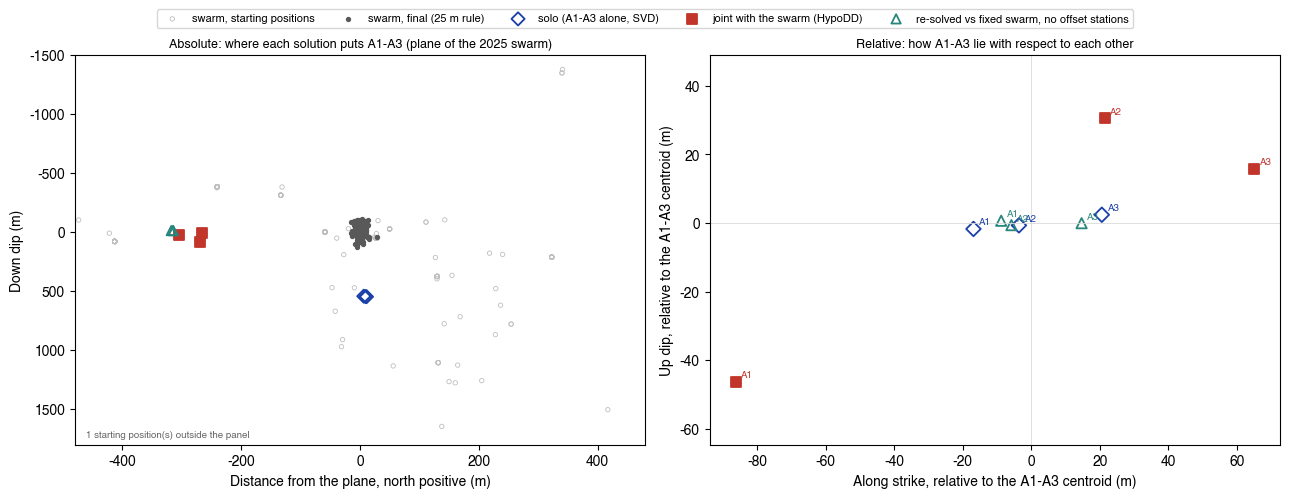

In [9]:
def ll_to_plane(k, lat, lon, dep):
    r25 = CAT[k][CAT[k].event_id.isin(R25[k].event_id)]; lat0, lon0, z0 = r25.latitude.mean(), r25.longitude.mean(), r25.depth_km.mean()
    X = np.c_[(np.asarray(lon) - lon0) * 111.19e3 * np.cos(np.radians(lat0)), (np.asarray(lat) - lat0) * 111.19e3, (np.asarray(dep) - z0) * 1e3] - FR[k]['P']['center']
    P = FR[k]['P']; us = P['s'] if P['s'][0] > 0 else -P['s']; nv = P['normal'] if P['normal'][1] > 0 else -P['normal']
    return X @ us, -(X @ P['down']), X @ nv
k = '2019A_full'; SOL = sol.copy(); SOL['along_east'], SOL['up_dip'], SOL['normal'] = ll_to_plane(k, SOL.lat, SOL.lon, SOL.dep)
JNT = CAT[k][CAT[k].event_id.isin(AID)].copy(); JNT['event'] = JNT.event_id.map(AID)
RS = ROB[(ROB.run == k) & ROB.case.str.startswith('without offset')].copy()
CMP = pd.concat([SOL.assign(solution='solo (A1-A3 alone, SVD)')[['solution', 'event', 'along_east', 'up_dip', 'normal']],
                 JNT.assign(solution='joint with the swarm (HypoDD)')[['solution', 'event', 'along_east', 'up_dip', 'normal']],
                 RS.rename(columns={'along_east_m': 'along_east', 'up_dip_m': 'up_dip', 'normal_m': 'normal'}).assign(solution='re-solved vs fixed swarm, no offset stations')[['solution', 'event', 'along_east', 'up_dip', 'normal']]], ignore_index=True)
for c_ in ('along_east', 'up_dip', 'normal'): CMP[c_ + '_rel'] = CMP[c_] - CMP.groupby('solution')[c_].transform('mean')
def spread(g):
    X = g[['along_east', 'up_dip', 'normal']].to_numpy(); return max(np.linalg.norm(X[i] - X[j]) for i in range(len(X)) for j in range(i + 1, len(X)))
SPR = CMP.groupby('solution')[['along_east', 'up_dip', 'normal']].apply(spread).rename('largest separation among A1-A3 (m)')
CEN = CMP.groupby('solution')[['along_east', 'up_dip', 'normal']].mean().round(0).rename(columns=lambda c: 'centroid ' + c + ' (m)')
display(pd.concat([CEN, SPR.round(0)], axis=1))
ST0 = pd.read_csv(f'{J}/event.dat', sep=r'\s+', header=None).rename(columns={2: 'lat', 3: 'lon', 4: 'dep', 9: 'id'})
RL = pd.read_csv(f'{J}/hypoDD.reloc', sep=r'\s+', header=None).rename(columns={0: 'id', 1: 'lat', 2: 'lon', 3: 'dep'})
ST0['along_east'], ST0['up_dip'], ST0['normal'] = ll_to_plane(k, ST0.lat, ST0.lon, ST0.dep)
RL['along_east'], RL['up_dip'], RL['normal'] = ll_to_plane(k, RL.lat, RL.lon, RL.dep)
MV = ST0.merge(RL, on='id', suffixes=('_start', '_reloc')); MV['group'] = np.where(MV.id.isin(AIDS), 'A1-A3', 'swarm')
for c_ in ('along_east', 'up_dip', 'normal'): MV['d_' + c_] = MV[c_ + '_reloc'] - MV[c_ + '_start']
print('starting positions = the HYPOINVERSE location of each event (a detection takes its template\'s); joint-run move from start to final position (m):')
display(MV.groupby('group')[['d_along_east', 'd_up_dip', 'd_normal']].agg(['mean', 'std']).round(0))
sw0 = ST0[~ST0.id.isin(AIDS)]
print(f'spread of the swarm starting positions (1 sd): along strike {sw0.along_east.std():.0f} m, up dip {sw0.up_dip.std():.0f} m, normal to the plane {sw0.normal.std():.0f} m')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sty = {'solo (A1-A3 alone, SVD)': ('D', '#1b3fa8'), 'joint with the swarm (HypoDD)': ('s', '#c1352b'), 're-solved vs fixed swarm, no offset stations': ('^', '#28867c')}
g25_ = CAT[k][CAT[k].event_id.isin(R25[k].event_id)]
ax[0].scatter(sw0.normal, -sw0.up_dip, s=10, facecolor='none', edgecolor='0.75', lw=0.6, label='swarm, starting positions')
ax[0].scatter(g25_.normal, -g25_.up_dip, s=8, color='0.35', label='swarm, final (25 m rule)')
for sname, (mk, col) in sty.items():
    q = CMP[CMP.solution == sname]; ax[0].scatter(q.normal, -q.up_dip, marker=mk, s=45, facecolor='none' if mk != 's' else col, edgecolor=col, lw=1.3, label=sname)
    ax[1].scatter(q.along_east_rel, q.up_dip_rel, marker=mk, s=55, facecolor='none' if mk != 's' else col, edgecolor=col, lw=1.3)
    for r_ in q.itertuples(): ax[1].annotate(r_.event, (r_.along_east_rel, r_.up_dip_rel), xytext=(4, 3), textcoords='offset points', fontsize=7, color=col)
YL = (-1500, 1800); off = int(((-sw0.up_dip < YL[0]) | (-sw0.up_dip > YL[1]) | (sw0.normal.abs() > 480)).sum())
ax[0].set_xlim(-480, 480); ax[0].set_ylim(YL[1], YL[0])
ax[0].text(0.02, 0.02, f'{off} starting position(s) outside the panel', transform=ax[0].transAxes, fontsize=7, color='0.4')
ax[0].set_xlabel('Distance from the plane, north positive (m)'); ax[0].set_ylabel('Down dip (m)'); ax[0].set_title('Absolute: where each solution puts A1-A3 (plane of the 2025 swarm)', fontsize=9)
ax[1].set_xlabel('Along strike, relative to the A1-A3 centroid (m)'); ax[1].set_ylabel('Up dip, relative to the A1-A3 centroid (m)'); ax[1].set_title('Relative: how A1-A3 lie with respect to each other', fontsize=9)
ax[1].axhline(0, color='0.85', lw=0.6); ax[1].axvline(0, color='0.85', lw=0.6); ax[1].set_aspect('equal', adjustable='datalim')
fig.legend(*ax[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=5, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()

**Reading section 5.**
- **Where they are.** Alone, the three events cannot move away from where they started, because every equation compares one of them with another. Their centroid stays exactly at the centroid of their starting positions, which are their templates' HYPOINVERSE locations. Those starting positions scatter by hundreds of meters (table above), so the solo run carries no information on whether A1–A3 lie on the 2025 plane. The ~300 m offset to the south is measured only through the 2019-to-2025 links, in the joint run and in the re-solves of section 3.
- **How they lie with respect to each other.** The mutual links have nearly the same delay at every station (spread 7–19 ms; the median delay is mostly an origin-time difference). So the three events are close together: within 38 m alone and within 24 m in the re-solve without the offset stations. The joint run spreads them over 168 m. The joint run's spacing is therefore set by the links to the swarm rather than by the events' own links, consistent with the bootstrap's 83–130 m east–west half-widths. Read the joint run's along-strike spread as uncertainty, not as a measured separation.
- **What survives.** The south offset (256–328 m over all station choices) and the swarm depth do. A1–A3 are best read as a tight group, within a few tens of meters of each other, offset parallel to the 2025 plane.

## Comprehensive summary

In [10]:
F = POS[POS.run == '2019A_full'].set_index('event'); N9 = POS[POS.run == '2019A'].set_index('event')
rob = ROB[(ROB.run == '2019A_full') & ROB.case.str.startswith(('all', 'without', 'stable'))]
summary = pd.DataFrame([
    ('Runs', '2019A: 2019 day with the 22 FMF stations only; 2019A_full: all 53 stations for 2019 (consistent with the swarm)'),
    ('A1-A3, 2019A_full: distance from the 2025 plane (m)', ', '.join(f'{e} {r.normal_m:+.0f} (N-S 95 % {r.ey95_m:.0f})' for e, r in F.iterrows()) + f'; 99 % of the 25 m swarm events within {FR["2019A_full"]["normal99"]:.0f} m'),
    ('A1-A3, 2019A_full: along strike / up dip (m)', ', '.join(f'{e} {r.along_east_m:+.0f} / {r.up_dip_m:+.0f}' for e, r in F.iterrows())),
    ('A1-A3, 2019A_full: links, under-constrained, 25 m rule', ', '.join(f'{e} {int(r.cc_links)}, {bool(r.under_constrained)}, {bool(r.in_25m_set)}' for e, r in F.iterrows())),
    ('A1-A3, 2019A (9 stations): distance from the plane (m)', ', '.join(f'{e} {r.normal_m:+.0f}' for e, r in N9.iterrows())),
    ('Stations with 2019-2025 offsets beyond ±20 ms (2019A_full)', ', '.join(f'{r.sta}.{r.ph} {r.median_res_ms:+.0f}' for r in ST[(ST.median_res_ms.abs() > 20) & (ST.links >= 10)].itertuples())),
    ('Re-solved distance from the plane, range over station choices (2019A_full)', ', '.join(f'{e} {g.normal_m.min():+.0f} to {g.normal_m.max():+.0f}' for e, g in rob.groupby('event'))),
    ('A1-A3 alone (SVD): largest separation; centroid', f'{SPR["solo (A1-A3 alone, SVD)"]:.0f} m; stays at the start (templates, inside the swarm): normal {CEN.loc["solo (A1-A3 alone, SVD)", "centroid normal (m)"]:+.0f} m'),
    ('Largest separation among A1-A3: joint / re-solved without offset stations', f'{SPR["joint with the swarm (HypoDD)"]:.0f} m / {SPR["re-solved vs fixed swarm, no offset stations"]:.0f} m'),
], columns=['quantity', 'value'])
display(summary)
sol_c = CEN.loc['solo (A1-A3 alone, SVD)']; mvA = MV[MV.group == 'A1-A3'].d_normal.mean(); mvS = MV[MV.group == 'swarm'].d_normal.mean()
print('Take-homes:')
print(f'1. Tied to the swarm, A1-A3 sit {-F.normal_m.max():.0f}-{-F.normal_m.min():.0f} m south of the 2025 plane at swarm depths; dropping offset or changed-epoch stations keeps {-rob.normal_m.max():.0f}-{-rob.normal_m.min():.0f} m.')
print(f'2. Relocated alone, they keep the centroid of their starting positions, i.e. their templates\' HYPOINVERSE locations ({sol_c["centroid normal (m)"]:+.0f} m from the plane, {-sol_c["centroid up_dip (m)"]:.0f} m below the final swarm centroid). Swarm starting positions scatter by {sw0.normal.std():.0f} m normal to the plane, so the three events alone cannot be placed relative to the swarm.')
print(f'3. In the joint run the swarm moves {mvS:+.0f} m and A1-A3 move {mvA:+.0f} m normal to the plane from their starting positions; the difference is what the 2019-2025 links measure.')
print(f'4. Mutual spacing: {SPR["solo (A1-A3 alone, SVD)"]:.0f} m alone, {SPR["re-solved vs fixed swarm, no offset stations"]:.0f} m re-solved, {SPR["joint with the swarm (HypoDD)"]:.0f} m joint. A1-A3 are a tight group; the joint along-strike spread is not resolved.')

,quantity,value
0,Runs,2019A: 2019 day with the 22 FMF stations only;...
1,"A1-A3, 2019A_full: distance from the 2025 plan...","A1 -269 (N-S 95 % 32), A2 -266 (N-S 95 % 35), ..."
2,"A1-A3, 2019A_full: along strike / up dip (m)","A1 +35 / -86, A2 +143 / -9, A3 +186 / -24"
3,"A1-A3, 2019A_full: links, under-constrained, 2...","A1 355, True, False, A2 347, False, False, A3 ..."
4,"A1-A3, 2019A (9 stations): distance from the p...","A1 -269, A2 -266, A3 -305"
5,Stations with 2019-2025 offsets beyond ±20 ms ...,"NAWB.S +93, JLSA.S -38, SUCA.S -20, KCH2.S -41..."
6,"Re-solved distance from the plane, range over ...","A1 -328 to -262, A2 -323 to -256, A3 -324 to -296"
7,A1-A3 alone (SVD): largest separation; centroid,"38 m; stays at the start (templates, inside th..."
8,Largest separation among A1-A3: joint / re-sol...,168 m / 24 m


Take-homes:
1. Tied to the swarm, A1-A3 sit 266-305 m south of the 2025 plane at swarm depths; dropping offset or changed-epoch stations keeps 256-328 m.
2. Relocated alone, they keep the centroid of their starting positions, i.e. their templates' HYPOINVERSE locations (+9 m from the plane, 544 m below the final swarm centroid). Swarm starting positions scatter by 229 m normal to the plane, so the three events alone cannot be placed relative to the swarm.
3. In the joint run the swarm moves +54 m and A1-A3 move -289 m normal to the plane from their starting positions; the difference is what the 2019-2025 links measure.
4. Mutual spacing: 38 m alone, 24 m re-solved, 168 m joint. A1-A3 are a tight group; the joint along-strike spread is not resolved.
